# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest** neural
crest) were scored in §01/§02 against the shared **union** control pool and graph-smoothed. Here we
render them as deliverables and evaluate **Gate 2** — does the embryonic module pattern appear? For Xing
the pattern is the **non-branching case**: Gast and pSom co-localise at the origin pole with Crest as an
**inverse terminal gradient** at the other, rather than a hub diverging into two competing arms. That
still **passes Gate 2 (GO, non-branching)** and leaves Gate 3 (branching-only) **NA**. Deliverable:
`signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_in = pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed upstream)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print('%s: %d/%d genes present' % (lab, g.size, feat[src].size))

cells: 8920 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 72/81 genes present
pSom: 80/98 genes present
Crest: 98/104 genes present


### Gate 2 — module geography on the manifold

Quantitative test of the module pattern for this dataset. Gast and pSom are **spatially
anti-correlated** (smoothed r ≈ −0.5, and ≈ −0.8 within the origin third) — genuine **cross-repression**
between adjacent origin sub-domains, *not* two diverging arms: §02 showed the manifold is one continuous
roundish mass whose branching-capable PPT fork count merely grows with node density (no stable
bifurcation). Per §1, the non-branching case *may still display cross-repression* (the Wu 2021
ratification), the discriminator being whether it resolves into two competing arms — here it does not.
The dominant developmental axis is **Gast/pSom (origin) → Crest (terminus)**: both Gast and pSom oppose
Crest spatially, along pseudotime Gast and pSom decline while Crest rises (Crest terminal, decile mean
pseudotime ≈ 0.9), and joint Crest-high co-expression with pSom is **depleted** (inverse gradient, not a
co-expression hub). Crest enriches the Gast/pSom-low terminus (not the Gast pole), so **no inversion
flag**. Pattern present on a non-branching manifold → **Gate 2 = GO**; no bifurcation → **Gate 3 = NA**.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print('  %s vs %s: r = %+.2f' % (a,b,r))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print('  %s: rho = %+.3f' % (s, rho))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Neural-crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print('joint pSom&Crest-high enrichment = %.2f (<1 = inverse gradient, not a hub)' % (joint/exp))
print('root-third Gast_sm vs pSom_sm: r = %+.2f (cross-repression between origin sub-domains)'
      % np.corrcoef(adata.obs['Gast_sm'][tn<=1/3], adata.obs['pSom_sm'][tn<=1/3])[0,1])
print('Gast/pSom cross-repress but do NOT split into two competing arms (see 02 PPT branching test);')
print('both oppose Crest; Crest terminal at the Gast/pSom-low pole -> no inversion flag')
print('Gate 2: embryonic axis present (Gast/pSom origin -> inverse terminal Crest) -> GO (non-branching)')
print('Gate 3: no stable bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.52
  Crest_sm vs Gast_sm: r = -0.32
  Crest_sm vs pSom_sm: r = -0.59
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.397
  pSom_sm: rho = -0.267
  Crest_sm: rho = +0.690
Neural-crest-high decile mean pseudotime = 0.92 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.28 (<1 = inverse gradient, not a hub)
root-third Gast_sm vs pSom_sm: r = -0.78 (cross-repression between origin sub-domains)
Gast/pSom cross-repress but do NOT split into two competing arms (see 02 PPT branching test);
both oppose Crest; Crest terminal at the Gast/pSom-low pole -> no inversion flag
Gate 2: embryonic axis present (Gast/pSom origin -> inverse terminal Crest) -> GO (non-branching)
Gate 3: no stable bifurcation -> NA


### Module maps (combined view, house linear layout)

`size=30` throughout (consistent across every deliverable panel), pseudotime left→right, **raw** scores
shown (graph-smoothed scores drive the quantitative test above, but the deliverable panels display the
raw per-cell scores).

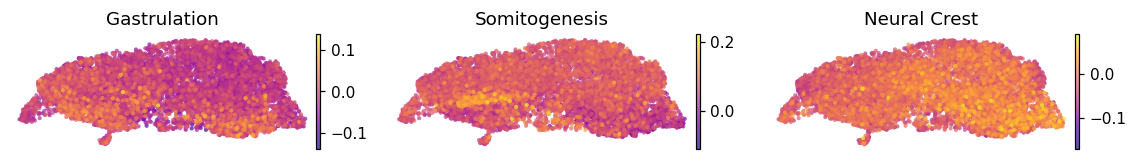

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout(); plt.show()

### Per-module signature figures + colorbars (deliverable)

House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, plasma, **raw** scores. Colorbar
ticks are data-driven from each score's range.

<cell6>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell6>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell6>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


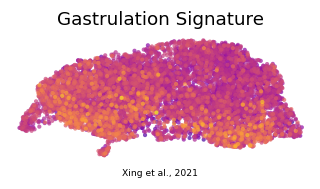

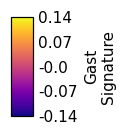

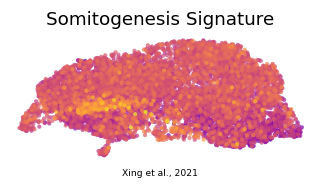

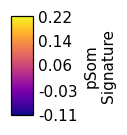

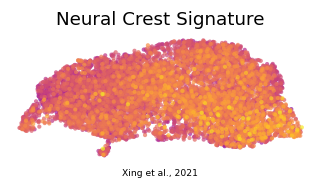

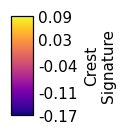

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Xing et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, '%s_signature.pdf' % m), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label('%s\nSignature' % m); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, '%s_colorbar.pdf' % m), bbox_inches='tight')
    print('saved %s_signature.pdf + colorbar' % m)
    plt.show()

### Save signatures data

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (8920, 17453)
